# KAN-based parameter estimation for the FitzHugh–Nagumo model

Companion to Yitao Fang, Hanwen Zhang and Nallappan Gunasekaran, *IEEE Transactions on Consumer Electronics* 72(1), 1623–1633 (2026). [Article](https://doi.org/10.1109/TCE.2026.3659339)

This notebook links the D1, D3 and D5 Hybrid KAN experiments to the equations, Algorithm 1, Table III and Figures 3–5. **Paper** labels a transcription from the article. **Reconstruction** labels a fresh calculation from the model and implementation choices documented below. The original checkpoints, D5 observation masks and run logs are unavailable.

Run all cells to inspect the selected case and verify the saved scores. Set **MODE** to **"one"** to refit that case or **"all"** to train one surrogate per tier and fit all four noise levels in each tier.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

SCENARIO = "D5"
SIGMA = 0.01
MODE = "saved"            # "saved", "one" or "all"
REBUILD_DATA = False      # Write a fresh dataset to runs/data and use it below
EXPORT_SVG = False        # Write the selected tier's trajectory figure to runs/

ROOT = Path.cwd()
DATA = ROOT / "data"
RESULTS = ROOT / "results"
RUNS = ROOT / "runs"
KEY = ["scenario", "sigma", "method"]
SCORES = ["rmse", "mae", "r2"]
PARAMS = ["a", "b", "tau", "I"]
if SCENARIO not in ("D1", "D3", "D5") or SIGMA not in (0.0001, 0.001, 0.01, 0.1):
    raise ValueError("Choose a published tier and noise level.")
if MODE not in ("saved", "one", "all"):
    raise ValueError("MODE must be 'saved', 'one' or 'all'.")

## Table III · Compare published and reconstructed scores by condition

The published table contains the 12 Hybrid KAN rows transcribed from Table III. Each row is paired with the reconstruction for that tier and noise scale. All three metrics score reconstructed state trajectories against the noisy observations used to fit them. The corresponding parameter estimates appear later in the notebook. [Published values](results/table_iii.csv) · [New calculations and termination status](results/reconstruction.csv)

In [2]:
published = pd.read_csv(RESULTS / "table_iii.csv")
archived = pd.read_csv(RESULTS / "reconstruction.csv", keep_default_na=False,
                       na_values={k: [""] for k in SCORES})
estimates = pd.read_csv(RESULTS / "estimates.csv")
paired = published.merge(archived, on=KEY, how="outer", validate="one_to_one",
                         suffixes=("_paper", "_new"), indicator=True)
assert len(paired) == 12 and paired["_merge"].eq("both").all()
assert paired["method"].eq("Hybrid KAN").all()

def compare(results):
    selected = results.query("scenario == @SCENARIO and sigma == @SIGMA").iloc[0]
    reference = published.query("scenario == @SCENARIO and sigma == @SIGMA").iloc[0]
    table = pd.DataFrame({
        "Paper": reference[SCORES].astype(float).to_numpy(),
        "Reconstruction": selected[SCORES].astype(float).to_numpy()
    }, index=["RMSE", "MAE", "R²"])
    table["Reconstruction − paper"] = table["Reconstruction"] - table["Paper"]
    display(table.style.format(precision=6, na_rep="—"))
    if selected["status"] == "failed":
        print(selected["failure"])
    elif selected["window_limits_s"]:
        ends = str(selected["window_limits_s"]).replace("|", ", ")
        print(f"Refinement reached the iteration limit at {ends} s.")

print(f"{SCENARIO} · noise scale {SIGMA:g}")
compare(archived)

D5 · noise scale 0.01


,Paper,Reconstruction,Reconstruction − paper
RMSE,0.020490,0.019322,-0.001168
MAE,0.015990,0.012993,-0.002997
R²,0.999600,0.999656,0.000056


Refinement reached the iteration limit at 10, 25 s.


## Equations (5)–(6) and Table II · Model and grid

The estimated vector in each segment is $(a,b,\tau,I)$. The two states satisfy $\dot u=u-u^3/3-v+I+d(t)$ and $\dot v=(u+a-bv)/\tau$. The effective current $I$ includes the constant bias $E$ of Eq. (6), as in the supplied scripts. On every known segment boundary, the next Dormand–Prince solve starts at the preceding segment’s final state. The 1,000-point grid, initial state and integrator tolerances follow Table II.

| Tier | Parameter segments (end times in seconds) | Observations | Hidden widths |
| --- | --- | --- | --- |
| D1 · IV.A and Table II | 12.5, 25 | Gaussian at all times | 32, 32 |
| D3 · IV.B | 8, 16, 25 | Gaussian at all times | 32, 32 |
| D5 · IV.C | 5, 10, 15, 20, 25 | Student’s $t_3$ with scale $\sigma$, 800 observed times | 48, 32, 16 |

The introduction also describes a one-segment D1; the numerical protocol above follows Section IV.A and Table II. Section III.B’s five-segment example supplies D5’s refinement windows of 5, 10 and 25 s. For D1 the windows end at its two boundaries, as in the supplied script. For D3, whose individual window ends are unspecified, this reconstruction uses 8, 16 and 25 s.

In [3]:
import csv
from pathlib import Path

import numpy as np
from scipy.integrate import solve_ivp

BASE = np.array([0.7, 0.8, 5.0, 0.5])
Y0 = np.array([-1.0, 1.0])
TIME = np.linspace(0.0, 25.0, 1000)
SEGMENT_ENDS = {
    "D1": (12.5, 25.0),
    "D3": (8.0, 16.0, 25.0),
    "D5": (5.0, 10.0, 15.0, 20.0, 25.0),
}
WINDOWS = {"D1": (12.5, 25.0), "D3": (8.0, 16.0, 25.0), "D5": (5.0, 10.0, 25.0)}
# The author scripts supply these observation seeds and training augmentation scales.
NOISE_SEEDS = {
    "D1": {0.0001: 1559, 0.001: 1430, 0.01: 1933, 0.1: 1832},
    "D3": {0.0001: 1125, 0.001: 2945, 0.01: 9222, 0.1: 2139},
    "D5": {0.0001: 644, 0.001: 144, 0.01: 401, 0.1: 796},
}
TRAIN_NOISE = {"D1": 0.01, "D3": 0.01, "D5": 0.02}


def forcing(scenario, t):
    """Known periodic drive; t is a scalar or an array in seconds."""
    drive = 0.3 * np.sin((2 * np.pi / 5) * t)
    if scenario == "D5":
        drive = drive + 0.1 * np.sin((2 * np.pi / 3.5) * t)
    return drive


def fhn_rhs(t, y, p, scenario):
    """Use I as the effective segment current, with the constant bias E absorbed into I."""
    u, v = y
    a, b, tau, current = p
    return np.array([u - u**3 / 3 - v + current + forcing(scenario, t),
                     (u + a - b * v) / tau])


def simulate(scenario, params, times=TIME):
    """Return states with shape (2, len(times)), carrying the state across segment boundaries."""
    ends = SEGMENT_ENDS[scenario]
    params = np.asarray(params, dtype=float).reshape(len(ends), 4)
    times = np.asarray(times, dtype=float)
    if (times.ndim != 1 or not times.size or not np.isfinite(times).all()
            or times[0] < 0 or times[-1] > ends[-1] or np.any(np.diff(times) <= 0)):
        raise ValueError("Sample times must increase within [0, 25].")
    if not np.isfinite(params).all() or np.any(params[:, 2] <= 0):
        raise ValueError("Supply finite parameters with positive time scales.")
    result = np.empty((2, len(times)))
    state = Y0.copy()
    start = 0.0
    offset = 0
    if times[0] == 0:
        result[:, 0] = state
        offset = 1
    for end, p in zip(ends, params):
        if offset == len(times):
            break
        stop = min(end, times[-1])
        index = times.searchsorted(stop, side="right")
        requested = times[offset:index]
        # The endpoint provides the exact restart time even when it falls between samples.
        sample_grid = requested if requested.size and requested[-1] == stop else np.append(requested, stop)
        sol = solve_ivp(fhn_rhs, (start, stop), state, args=(p, scenario),
                        method="RK45", t_eval=sample_grid, rtol=1e-6, atol=1e-9)
        if not sol.success:
            raise RuntimeError(f"FHN integration failed in {scenario}: {sol.message}")
        result[:, offset:index] = sol.y[:, :len(requested)]
        state, start, offset = sol.y[:, -1], end, index
    return result

### Algorithm 1, lines 3–7 · Training and observation generation

Each tier has one set of true segment parameters and four noise realizations. True parameters vary independently by up to 20% about $(0.7,0.8,5.0,0.5)$. Training uses 200 independently simulated trajectories, parameter perturbations of up to 30%, and small Gaussian target perturbations. The supplied scripts give the observation seeds, augmentation scales and drive frequencies. The implementation uses seed 0 for the ground truth and surrogate training.

Section IV.C overrides Algorithm 1’s general Gaussian observation step for D5. The two D5 channels receive independent $t_3$ draws of scale $\sigma$, giving variance $3\sigma^2$. This reconstruction omits exactly 200 entire time points per D5 case. The two channels share a mask. Every time index is eligible, including both endpoints. The independent mask seed for each case is the observation seed plus 100,000. This specifies a new, repeatable mask.

In [4]:
def true_parameters(scenario):
    rng = np.random.RandomState(0)
    return BASE * (1 + 0.2 * (2 * rng.rand(len(SEGMENT_ENDS[scenario]), 4) - 1))


def make_case(scenario, sigma):
    """Build one seeded case. Missing times are shared across both D5 channels."""
    params = true_parameters(scenario)
    truth = simulate(scenario, params)
    seed = NOISE_SEEDS[scenario][sigma]
    rng = np.random.RandomState(seed)
    mask = np.ones(TIME.size, dtype=bool)
    if scenario == "D5":
        # Section IV.C defines sigma as a t-distribution scale, giving variance 3*sigma**2.
        noise = sigma * rng.standard_t(3, size=truth.shape)
        # Release convention: independent mask per case, including endpoints in the draw.
        mask_rng = np.random.RandomState(100000 + seed)
        mask[mask_rng.choice(TIME.size, size=TIME.size // 5, replace=False)] = False
    else:
        noise = sigma * rng.standard_normal(truth.shape)
    obs = truth + noise
    obs[:, ~mask] = np.nan
    return dict(scenario=scenario, sigma=sigma, seed=seed, time=TIME.copy(), truth=truth,
                observed=obs, mask=mask, parameters=params)


def training_data(scenario, samples=200, train_points=1000, seed=0):
    """Return source-format input and target matrices for independent training trajectories."""
    if samples < 1 or train_points < 2:
        raise ValueError("Training requires positive sample count and at least two time points.")
    t = np.linspace(0., 25., train_points)
    ends = SEGMENT_ENDS[scenario]
    active = np.searchsorted(ends, t, side="left")
    rng = np.random.RandomState(seed)
    # In the supplied scripts the training stream begins after the evaluation parameter draw.
    rng.rand(len(ends), 4)
    X = np.empty((samples, train_points, 5), dtype=np.float32)
    Y = np.empty((samples, train_points, 2), dtype=np.float32)
    for i in range(samples):
        params = BASE * (1 + 0.3 * (2 * rng.rand(len(ends), 4) - 1))
        X[i, :, 0] = t
        X[i, :, 1:] = params[active]
        Y[i] = simulate(scenario, params, t).T + TRAIN_NOISE[scenario] * rng.randn(train_points, 2)
    return X.reshape(-1, 5), Y.reshape(-1, 2)

In [5]:
def write_data(directory):
    """Write the clean reference, noisy observations, sample mask and parameter labels."""
    directory = Path(directory)
    directory.mkdir(parents=True, exist_ok=True)
    with (directory / "parameters.csv").open("w", encoding="utf-8", newline="") as file:
        writer = csv.writer(file, lineterminator="\n")
        writer.writerow(["scenario", "segment", "t_start", "t_end", "a", "b", "tau", "I"])
        for scenario, ends in SEGMENT_ENDS.items():
            params = true_parameters(scenario)
            for i, (left, right) in enumerate(zip((0., *ends[:-1]), ends)):
                writer.writerow([scenario, i + 1, left, right, *params[i]])
    with (directory / "observations.csv").open("w", encoding="utf-8", newline="") as file:
        writer = csv.writer(file, lineterminator="\n")
        writer.writerow(["scenario", "sigma", "seed", "time", "segment", "observed",
                         "u_true", "v_true", "u_obs", "v_obs"])
        for scenario, noise_seeds in NOISE_SEEDS.items():
            segments = np.searchsorted(SEGMENT_ENDS[scenario], TIME, side="left") + 1
            for sigma, seed in noise_seeds.items():
                case = make_case(scenario, sigma)
                for i, t in enumerate(TIME):
                    keep = case["mask"][i]
                    obs = case["observed"][:, i] if keep else ("", "")
                    writer.writerow([scenario, sigma, seed, t, segments[i], int(keep),
                                     *case["truth"][:, i], *obs])


def read_case(directory, scenario, sigma):
    """Read one pair of state trajectories and its ground-truth parameter labels."""
    directory = Path(directory)
    with (directory / "observations.csv").open(encoding="utf-8", newline="") as file:
        rows = [r for r in csv.DictReader(file) if r["scenario"] == scenario and float(r["sigma"]) == sigma]
    if not rows:
        raise ValueError(f"No case for {scenario} with noise scale {sigma}.")
    with (directory / "parameters.csv").open(encoding="utf-8", newline="") as file:
        params = [[float(r[k]) for k in ("a", "b", "tau", "I")]
                  for r in csv.DictReader(file) if r["scenario"] == scenario]
    time = np.array([float(r["time"]) for r in rows])
    mask = np.array([r["observed"] == "1" for r in rows])
    truth = np.array([[float(r[k]) for r in rows] for k in ("u_true", "v_true")])
    obs = np.array([[float(r[k]) if r[k] else np.nan for r in rows] for k in ("u_obs", "v_obs")])
    return dict(scenario=scenario, sigma=sigma, seed=int(rows[0]["seed"]), time=time,
                truth=truth, observed=obs, mask=mask, parameters=np.array(params))

In [6]:
if REBUILD_DATA:
    DATA = RUNS / "data"
    write_data(DATA)
case = read_case(DATA, SCENARIO, SIGMA)
print(f"Observation seed {case['seed']} | {case['mask'].sum()} of {len(case['time'])} times retained")

Observation seed 401 | 800 of 1000 times retained


## Section III.A · Cubic spline surrogate

Equation (7) writes each layer as a vector of univariate spline evaluations followed by a mixing matrix. The prose also describes a separate spline on every incoming edge. Here Eq. (7) determines the sharing pattern: each input coordinate has its own cubic spline and each output learns its own mixing weights. Hidden layers use $\tanh$ and the output is linear. D5 uses dropout with probability 0.1. The article’s approximate parameter count does not uniquely identify its original network.

The code uses eight distinct breakpoints per spline, learned positive spacings, and repeated end knots. It initializes the cubic spline to the identity, scales the first-layer inputs to their training ranges and holds endpoint values constant outside the spline domain. These choices specify the boundary behavior and initialization omitted from the article. Equation (12) supplies the Huber loss plus an L1 penalty on the spline control coefficients. The full run uses 60 epochs. Batch size 2,048, learning rate 0.003 and AdamW weight decay $10^{-4}$ follow the supplied scripts.

In [7]:
import torch
from torch import nn
from torch.nn import functional as F
from scipy.optimize import Bounds, minimize


class CubicSplineBank(nn.Module):
    """One cubic B-spline per input in s(x) of Eq. (7), with eight distinct breakpoints."""

    def __init__(self, features):
        super().__init__()
        self.log_spacing = nn.Parameter(torch.zeros(features, 7))
        grid = torch.linspace(-1., 1., 8)
        padded = torch.cat((grid[:1].repeat(3), grid, grid[-1:].repeat(3)))
        # Greville abscissae initialize a degree-three B-spline to the identity.
        self.coeff = nn.Parameter(padded[1:-1].unfold(0, 3, 1).mean(-1).repeat(features, 1))
        self.register_buffer("row", torch.arange(features), persistent=False)

    def pieces(self):
        """Convert the open cubic B-splines to local Taylor coefficients."""
        widths = 2 * self.log_spacing.softmax(dim=1)
        left = -torch.ones_like(widths[:, :1])
        grid = torch.cat((left, left + widths.cumsum(1)), dim=1)
        knots = torch.cat((left.expand(-1, 3), grid, grid[:, -1:].expand(-1, 3)), 1)
        c = self.coeff
        # Successive derivatives of a B-spline are lower-degree B-splines.
        d1 = 3 * c.diff(dim=1) / (knots[:, 4:-1] - knots[:, 1:-4])
        d2 = 2 * d1.diff(dim=1) / (knots[:, 4:-2] - knots[:, 2:-4])
        d3 = d2.diff(dim=1) / widths
        # The second derivative interpolates d2 linearly on each interval.
        step_d1 = 0.5 * widths * (d2[:, :-1] + d2[:, 1:])
        slope = torch.cat((d1[:, :1], d1[:, :1] + step_d1.cumsum(1)), 1)[:, :-1]
        step_c = widths * slope + widths.square() * (2*d2[:, :-1] + d2[:, 1:]) / 6
        value = torch.cat((c[:, :1], c[:, :1] + step_c.cumsum(1)), 1)[:, :-1]
        return grid, torch.stack((value, slope, d2[:, :-1] / 2, d3 / 6), dim=-1)

    def forward(self, x):
        grid, coeff = self.pieces()
        # Hold endpoint values outside the fitted spline domain.
        x = x.T.contiguous().clamp(-1., 1.)
        span = (torch.searchsorted(grid.contiguous(), x) - 1).clamp(0, 6)
        offset = x - grid.gather(1, span)
        c0, c1, c2, c3 = coeff[self.row[:, None], span].unbind(-1)
        return (c0 + offset * (c1 + offset * (c2 + offset * c3))).T


class PaperKAN(nn.Module):
    def __init__(self, scenario):
        super().__init__()
        hidden = (48, 32, 16) if scenario == "D5" else (32, 32)
        dims = (5, *hidden, 2)
        self.splines = nn.ModuleList(CubicSplineBank(n) for n in dims[:-1])
        self.mixing = nn.ModuleList(nn.Linear(n, m) for n, m in zip(dims, dims[1:]))
        self.dropout = nn.Dropout(0.1 if scenario == "D5" else 0.0)
        # Scale (t, a, b, tau, I) to its simulation ranges before spline evaluation.
        self.register_buffer("center", torch.tensor([12.5, *BASE], dtype=torch.float32))
        self.register_buffer("scale", torch.tensor([12.5, *(0.3*BASE)], dtype=torch.float32))

    def forward(self, x):
        x = (x - self.center) / self.scale
        for i, (spline, mixing) in enumerate(zip(self.splines, self.mixing)):
            x = self.dropout(mixing(spline(x)))
            if i + 1 < len(self.mixing):
                x = torch.tanh(x)
        return x


def train_kan(scenario, seed=0, samples=200, epochs=60, train_points=1000, device="cpu"):
    X, Y = training_data(scenario, samples=samples, train_points=train_points, seed=seed)
    X, Y = torch.from_numpy(X).to(device), torch.from_numpy(Y).to(device)
    torch.manual_seed(seed)
    network = PaperKAN(scenario).to(device)
    optimizer = torch.optim.AdamW(network.parameters(), lr=0.003, weight_decay=1e-4)
    for epoch in range(epochs):
        for batch in torch.randperm(len(X), device=device).split(2048):
            optimizer.zero_grad(set_to_none=True)
            data_loss = F.smooth_l1_loss(network(X[batch]), Y[batch], beta=1.0)
            penalty = sum(spline.coeff.abs().sum() for spline in network.splines)
            (data_loss + 1e-3 * penalty).backward()
            optimizer.step()
    return network.eval().double()

### Algorithm 1, lines 8–21 · Two-stage estimation

L-BFGS-B starts from 90% of the base parameters in every segment and minimizes the squared residuals of the surrogate at retained times. Automatic differentiation supplies the gradient. The constant endpoint extension can create equivalent coarse minimizers outside the training range. For this implementation, the nearest range endpoint represents a minimizer on each such plateau.

The next stage uses SciPy’s trust-region constrained optimizer. At each expanding window it refits only the completed segments, keeps the later parameters fixed, and sums Huber losses with $\delta=1$ on the available observations. Integration ends at the exact window boundary even if no observation lies there. The source-script budget is 100 iterations per window with gradient tolerance $10^{-6}$. A fit can return finite parameters when it reaches this limit. The scores table lists all such window ends in seconds.

In [8]:
def fit_hybrid(scenario, model, case, maxiter=100):
    ends = np.asarray(SEGMENT_ENDS[scenario])
    time, mask = case["time"], case["mask"]
    observed_times = time[mask]
    observations = case["observed"][:, mask]
    device = model.center.device
    t = torch.as_tensor(observed_times, dtype=torch.float64, device=device)
    target = torch.as_tensor(observations.T, dtype=torch.float64, device=device)
    active = torch.as_tensor(ends.searchsorted(observed_times), device=device)

    def coarse_objective(p):
        flat = torch.tensor(p, dtype=torch.float64, device=device, requires_grad=True)
        features = torch.cat((t[:, None], flat.view(-1, 4)[active]), 1)
        loss = (model(features) - target).square().sum()
        grad, = torch.autograd.grad(loss, flat)
        return loss.item(), grad.detach().cpu().numpy()

    # Section II bounds require positive a, b and tau, with unrestricted current.
    positive = np.finfo(float).tiny
    lower = np.tile([positive, positive, 1e-6, -np.inf], len(ends))
    upper = np.full_like(lower, np.inf)
    p0 = np.tile(0.9 * BASE, len(ends))
    coarse = minimize(coarse_objective, p0, method="L-BFGS-B", jac=True,
                      bounds=Bounds(lower, upper))
    # Endpoint extension makes all values beyond each input interval indistinguishable
    # to the surrogate. Choose the nearest boundary to start the physical fit.
    center = model.center.detach().cpu().numpy()[1:]
    scale = model.scale.detach().cpu().numpy()[1:]
    coarse_params = coarse.x.reshape(-1, 4).clip(center - scale, center + scale)
    parameters = coarse_params.ravel().copy()
    diagnostics = []

    def record(result, stage, end):
        diagnostics.append(dict(stage=stage, window_end=float(end), success=bool(result.success),
                                message=str(result.message), iterations=int(result.nit),
                                objective=float(result.fun)))

    record(coarse, "Coarse KAN", ends[-1])
    for end in WINDOWS[scenario]:
        free = 4 * np.count_nonzero(ends <= end)
        in_window = observed_times <= end
        tw, yw = observed_times[in_window], observations[:, in_window]
        # Integrate to the exact window end even if it is an unsampled or omitted time.
        solve_times = tw if tw[-1] == end else np.append(tw, end)

        def huber_prefix(p):
            trial = parameters.copy()
            trial[:free] = p
            # simulate() starts from y0 and restarts at each known segment boundary.
            pred = simulate(scenario, trial, solve_times)[:, :len(tw)]
            error = np.abs(pred - yw)
            return np.where(error <= 1., 0.5 * error**2, error - 0.5).sum()

        result = minimize(huber_prefix, parameters[:free], method="trust-constr",
                          bounds=Bounds(lower[:free], upper[:free], keep_feasible=True),
                          options={"maxiter": maxiter, "gtol": 1e-6})
        parameters[:free] = result.x
        record(result, "Huber ODE refinement", end)
    return dict(coarse=coarse_params, parameters=parameters.reshape(-1, 4),
                trajectory=simulate(scenario, parameters, time), diagnostics=diagnostics)

## Section III.C · Fit, score and reconstruct

Equations (14)–(16) pool the retained entries of both observed states. Algorithm 1, line 22 specifies the noisy observations as the reference. R² uses a single pooled mean. A missing D5 time contributes to neither estimation losses nor metrics.

In **saved** mode, the following cells integrate the stored parameter estimates and independently verify the three scores of every completed case. In **one** or **all** mode, the code trains once per selected tier, fits the same observations and writes the new scores and estimates under **runs/**. The saved release used a single CPU thread and PyTorch training seed 0.

In [9]:
def trajectory_scores(case, states):
    mask = case["mask"]
    observed = case["observed"][:, mask]
    residual = states[:, mask] - observed
    return dict(rmse=np.sqrt(np.mean(residual**2)), mae=np.mean(np.abs(residual)),
                r2=1 - np.sum(residual**2) / np.sum((observed - observed.mean())**2))


def result_rows(case, params=None, prediction=None, diagnostics=(), failure=""):
    case_id = dict(scenario=case["scenario"], sigma=case["sigma"], method="Hybrid KAN", seed=case["seed"])
    windows = [d for d in diagnostics if d["stage"] == "Huber ODE refinement"]
    limited = [f"{d['window_end']:g}" for d in windows if not d["success"]]
    scores = dict(rmse=np.nan, mae=np.nan, r2=np.nan) if failure else trajectory_scores(case, prediction)
    row = dict(**case_id, observed_times=int(case["mask"].sum()),
               status="failed" if failure else "completed", **scores,
               window_limits_s="|".join(limited), failure=failure)
    estimates = []
    if params is not None:
        for j, p in enumerate(params, 1):
            estimates.append({**case_id, "segment": j, **dict(zip(("a", "b", "tau", "I"), p))})
    return row, estimates


def run_experiments(cases, directory):
    """Fit each selected noise realization with its tier's shared surrogate."""
    score_rows, parameter_rows = [], []
    for tier in dict.fromkeys(scenario for scenario, _ in cases):
        model = train_kan(tier)
        for scenario, sigma in cases:
            if scenario != tier:
                continue
            sample = read_case(directory, tier, sigma)
            try:
                fit = fit_hybrid(tier, model, sample)
                row, vectors = result_rows(sample, fit["parameters"], fit["trajectory"], fit["diagnostics"])
            except (FloatingPointError, np.linalg.LinAlgError, RuntimeError) as error:
                row, vectors = result_rows(sample, failure=str(error))
            score_rows.append(row)
            parameter_rows.extend(vectors)
    columns = [*KEY, "seed", "segment", *PARAMS]
    return pd.DataFrame(score_rows), pd.DataFrame(parameter_rows, columns=columns)

In [10]:
torch.set_num_threads(1)
if MODE in ("one", "all"):
    cases = [(SCENARIO, SIGMA)] if MODE == "one" else [
        (tier, sigma) for tier in NOISE_SEEDS for sigma in NOISE_SEEDS[tier]]
    scores_now, estimates_now = run_experiments(cases, DATA)
    RUNS.mkdir(exist_ok=True)
    stem = f"{SCENARIO}_{SIGMA:g}" if MODE == "one" else "all"
    scores_now.to_csv(RUNS / f"{stem}_scores.csv", index=False, lineterminator="\n")
    estimates_now.to_csv(RUNS / f"{stem}_parameters.csv", index=False, lineterminator="\n")
    compare(scores_now)
else:
    scores_now, estimates_now = archived, estimates

checked = 0
for row in scores_now.itertuples(index=False):
    if row.status != "completed":
        continue
    sample = read_case(DATA, row.scenario, row.sigma)
    match = estimates_now.query(
        "scenario == @row.scenario and sigma == @row.sigma and method == @row.method"
    ).sort_values("segment")
    prediction = simulate(row.scenario, match[PARAMS].to_numpy(), sample["time"])
    recomputed = trajectory_scores(sample, prediction)
    np.testing.assert_allclose([recomputed[s] for s in SCORES], [getattr(row, s) for s in SCORES],
                               rtol=1e-8, atol=1e-10)
    checked += 1
print(f"Verified RMSE, MAE and R² from the parameter estimates for {checked} completed fits.")

Verified RMSE, MAE and R² from the parameter estimates for 12 completed fits.


### Inspect parameter recovery

Table III measures trajectory error. This separate comparison shows the known simulated parameters and the estimated values for each segment of the selected case.

In [11]:
selected = estimates_now.query("scenario == @SCENARIO and sigma == @SIGMA")
truth_values = pd.DataFrame(case["parameters"], columns=PARAMS)
truth_values["method"] = "Generating values"
truth_values["segment"] = np.arange(1, len(truth_values) + 1)
display(pd.concat([truth_values, selected[["method", "segment", *PARAMS]]])
        .set_index(["segment", "method"]).sort_index().round(5))

a        b      tau        I
segment method                                               
1       Generating values  0.71367  0.86886  5.20553  0.50898
        Hybrid KAN         0.74686  1.05430  5.37051  0.50165
2       Generating values  0.67862  0.84669  4.87517  0.57835
        Hybrid KAN         0.66791  0.89547  4.92830  0.58572
3       Generating values  0.82983  0.76270  5.58345  0.50578
        Hybrid KAN         0.72354  0.83227  4.97759  0.51254
4       Generating values  0.71905  0.93619  4.14207  0.41743
        Hybrid KAN         0.85829  1.03851  4.20493  0.40523
5       Generating values  0.56566  0.90644  5.55631  0.57400
        Hybrid KAN         0.69835  0.92149  4.77588  0.57207

## Figures 4 and 5 · State trajectories and phase portraits

The layout follows the article’s paired time-series and phase panels. D1 corresponds to Figure 4 and D5 to Figure 5. Select D3 to draw the same diagnostic for the middle tier. Curves come from reconstructed parameters and the dots are the retained observations. The code reads the four saved KAN fits for the tier and overlays fresh estimates where available. Enable **EXPORT_SVG** to save this figure.

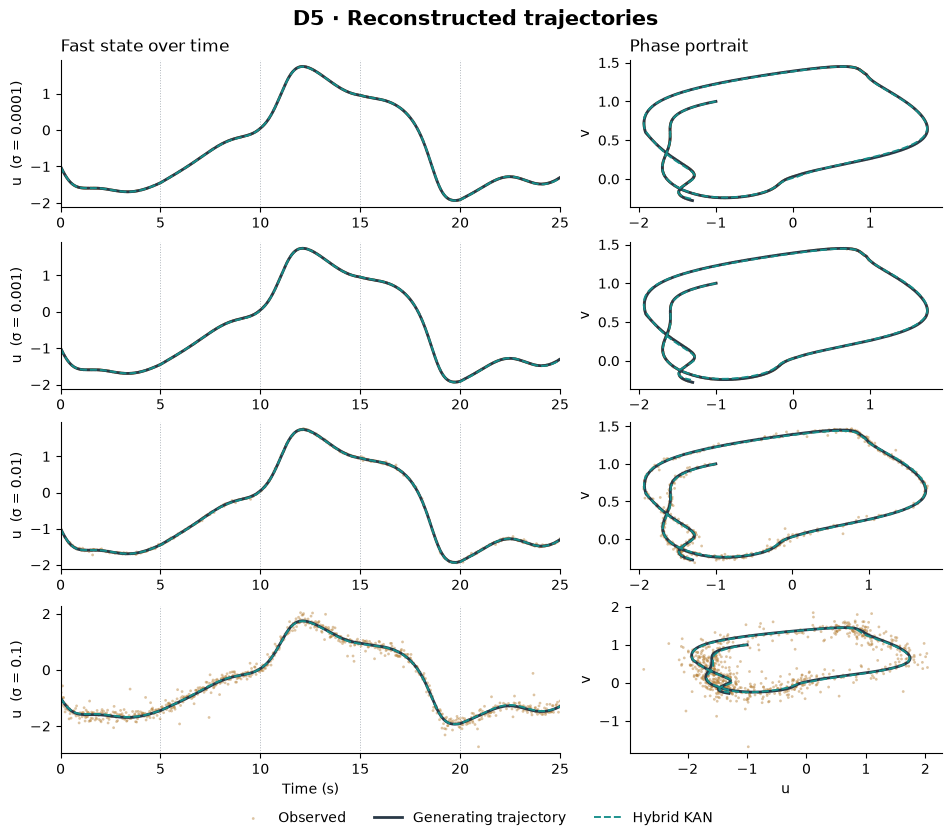

In [12]:
def plot_tier(tier):
    sigmas = sorted(NOISE_SEEDS[tier])
    fig, axes = plt.subplots(len(sigmas), 2, figsize=(9.4, 8.3), layout="constrained",
                             width_ratios=[1.6, 1])
    for i, sigma in enumerate(sigmas):
        sample = read_case(DATA, tier, sigma)
        row_filter = "scenario == @tier and sigma == @sigma and method == 'Hybrid KAN'"
        params = estimates_now.query(row_filter)
        if params.empty:
            attempted = scores_now.query(row_filter)
            if not attempted.empty:
                for ax in axes[i]:
                    ax.text(0.5, 0.5, "Fit failed", transform=ax.transAxes, ha="center")
                continue
            params = estimates.query(row_filter)
        states = simulate(tier, params.sort_values("segment")[PARAMS].to_numpy(), sample["time"])
        keep = sample["mask"]
        t, obs, true = sample["time"], sample["observed"], sample["truth"]
        for ax, dots, ref, fit in (
            (axes[i, 0], (t[keep], obs[0, keep]), (t, true[0]), (t, states[0])),
            (axes[i, 1], obs[:, keep], true, states),
        ):
            ax.scatter(*dots, s=4, color="#b57e34", alpha=0.45, edgecolors="none", label="Observed")
            ax.plot(*ref, lw=2.0, color="#293947", label="Generating trajectory")
            ax.plot(*fit, lw=1.35, ls="--", color="#168e8a", label="Hybrid KAN")
            ax.spines[["top", "right"]].set_visible(False)
        axes[i, 0].set(ylabel=f"u  (σ = {sigma:g})", xlim=(0, 25))
        axes[i, 1].set_ylabel("v")
        for edge in SEGMENT_ENDS[tier][:-1]:
            axes[i, 0].axvline(edge, color="#b0b6bc", lw=.7, ls=":", zorder=0)
    axes[0, 0].set_title("Fast state over time", loc="left")
    axes[0, 1].set_title("Phase portrait", loc="left")
    axes[-1, 0].set_xlabel("Time (s)")
    axes[-1, 1].set_xlabel("u")
    fig.suptitle(f"{tier} · Reconstructed trajectories", weight="bold", fontsize=15)
    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="outside lower center", ncol=3, frameon=False)
    if EXPORT_SVG:
        RUNS.mkdir(exist_ok=True)
        fig.savefig(RUNS / f"{tier}_trajectories.svg", bbox_inches="tight")
    plt.show()

plot_tier(SCENARIO)

### Figure 3 · Reported wall-clock times

These seconds are transcribed from Figure 3 for the publication’s computing environment. Hardware and timing boundaries affect wall-clock comparisons. This notebook trains one surrogate per tier and reuses it for the four noise cases.

In [13]:
timing = pd.DataFrame([[241.3, 310.2, 413.6, 551.5],
                       [448.1, 586.0, 827.2, 1103.0],
                       [844.6, 1103.1, 1551.1, 2068.1]],
                      index=["D1", "D3", "D5"], columns=[0.0001, 0.001, 0.01, 0.1])
display(timing.rename_axis(index="Tier", columns="Noise scale σ"))

Noise scale σ,0.0001,0.0010,0.0100,0.1000
Tier,,,,
D1,241.3,310.2,413.6,551.5
D3,448.1,586.0,827.2,1103.0
D5,844.6,1103.1,1551.1,2068.1
